In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the housing dataset
df = pd.read_csv("housing.csv")

# Display the first five rows
display(df.head())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset shape: (20640, 10)

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [2]:
# Step 2: Explore the dataset

# Check column names and data types
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check the target variable
print("\nTarget variable: median_house_value")
print(df["median_house_value"].describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Number of duplicate rows: 0

Target variable: median_house_value
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


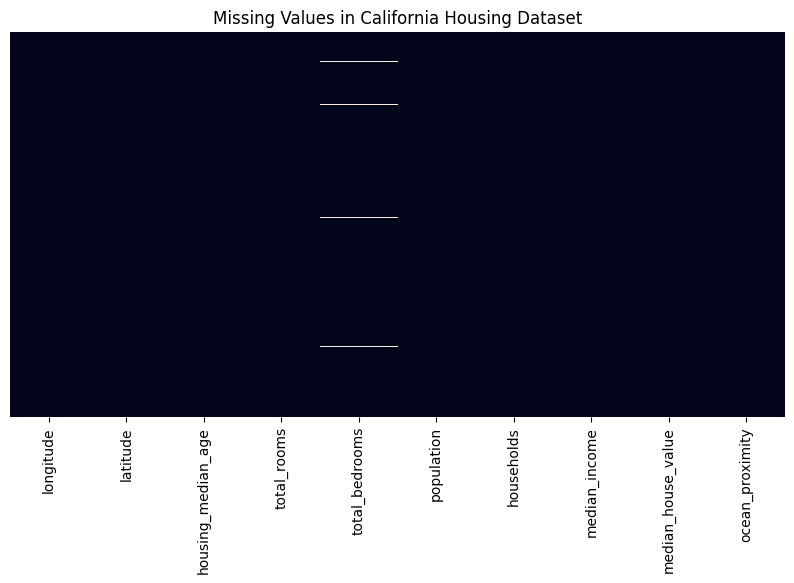

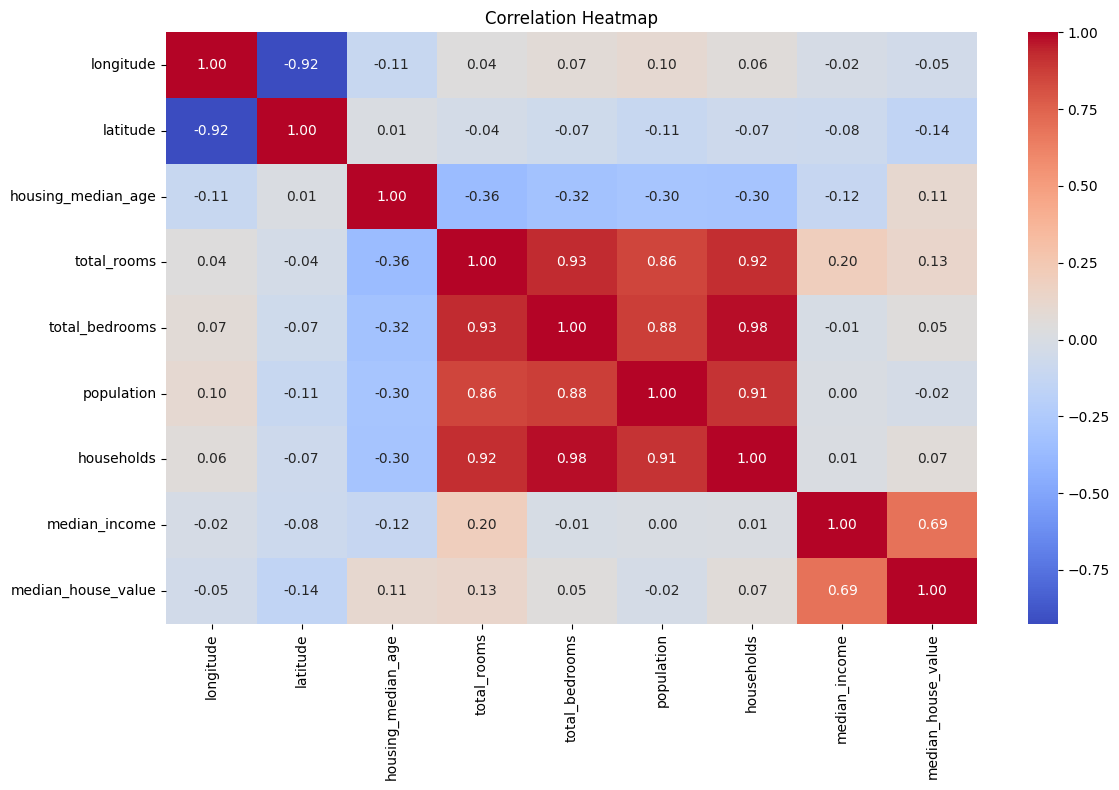

In [3]:
# Visualize missing values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in California Housing Dataset")
plt.show()

# Correlation heatmap for numerical columns
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [5]:
# Step 4: Prepare data and create interaction features

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Create a copy of the dataset
data = df.copy()

# Create interaction features
data["rooms_per_household"] = (
    data["total_rooms"] / data["households"].replace(0, np.nan)
)

data["bedrooms_per_room"] = (
    data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
)

data["population_per_household"] = (
    data["population"] / data["households"].replace(0, np.nan)
)

# Define features and target
X = data.drop("median_house_value", axis=1)
y = data["median_house_value"]

# Split before fitting preprocessing steps to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols = X_train.select_dtypes(exclude=np.number).columns

# Impute missing numerical values using training medians
num_imputer = SimpleImputer(strategy="median")
X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[numeric_cols]),
    columns=numeric_cols,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[numeric_cols]),
    columns=numeric_cols,
    index=X_test.index
)

# Impute categorical values using the most frequent category
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols,
    index=X_train.index
)
X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[categorical_cols]),
    columns=categorical_cols,
    index=X_test.index
)

# Combine the processed columns
X_train_clean = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_clean = pd.concat([X_test_num, X_test_cat], axis=1)

print("Training data shape:", X_train_clean.shape)
print("Testing data shape:", X_test_clean.shape)
print("Missing values in training data:", X_train_clean.isnull().sum().sum())
print("Missing values in testing data:", X_test_clean.isnull().sum().sum())

Training data shape: (16512, 12)
Testing data shape: (4128, 12)
Missing values in training data: 0
Missing values in testing data: 0


In [6]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Prepare the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(numeric_cols)),
        ("cat", OneHotEncoder(handle_unknown="ignore"), list(categorical_cols))
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_clean)
X_test_processed = preprocessor.transform(X_test_clean)

print("Preprocessing completed successfully!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed successfully!
Processed training shape: (16512, 16)
Processed testing shape: (4128, 16)


In [7]:
# Step 6: Train and tune regression models

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Ordinary Least Squares (OLS)
ols_model = LinearRegression()
ols_model.fit(X_train_processed, y_train)

# Ridge Regression with cross-validation
ridge_search = GridSearchCV(
    Ridge(),
    {"alpha": [0.1, 1, 10, 100, 1000]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_search.fit(X_train_processed, y_train)
ridge_model = ridge_search.best_estimator_

# Lasso Regression with cross-validation
lasso_search = GridSearchCV(
    Lasso(max_iter=10000),
    {"alpha": [0.1, 1, 10, 100, 1000]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_search.fit(X_train_processed, y_train)
lasso_model = lasso_search.best_estimator_

print("All three regression models trained successfully!")
print("Best Ridge alpha:", ridge_search.best_params_["alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["alpha"])

All three regression models trained successfully!
Best Ridge alpha: 1
Best Lasso alpha: 1


In [8]:
# Step 7: Evaluate regression models

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "OLS": ols_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

results_list = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    predictions[name] = y_pred

    results_list.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2 Score": r2_score(y_test, y_pred)
    })

results = pd.DataFrame(results_list)

display(results.round(3))

,Model,RMSE,MAE,R2 Score
0,OLS,69127.038,49645.492,0.635
1,Ridge,69134.965,49652.143,0.635
2,Lasso,69128.091,49646.429,0.635


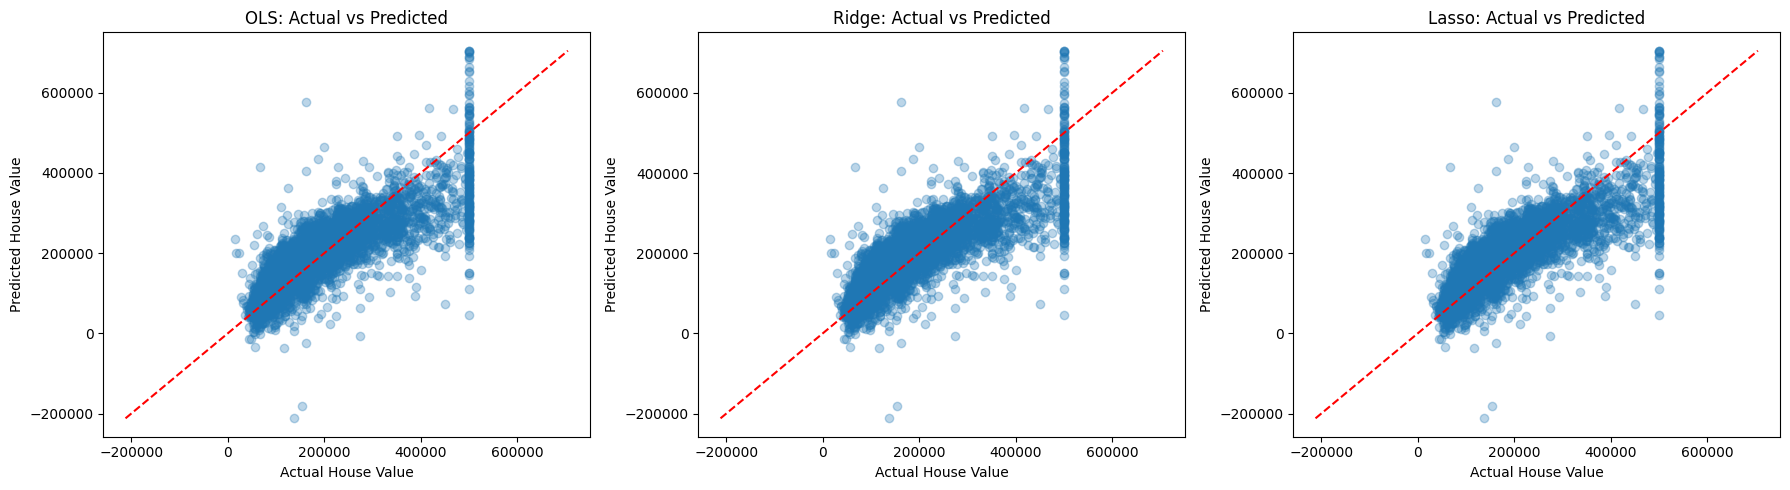

In [9]:
# Step 8: Actual vs predicted values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3)

    # Reference line for perfect predictions
    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())
    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.tight_layout()
plt.show()

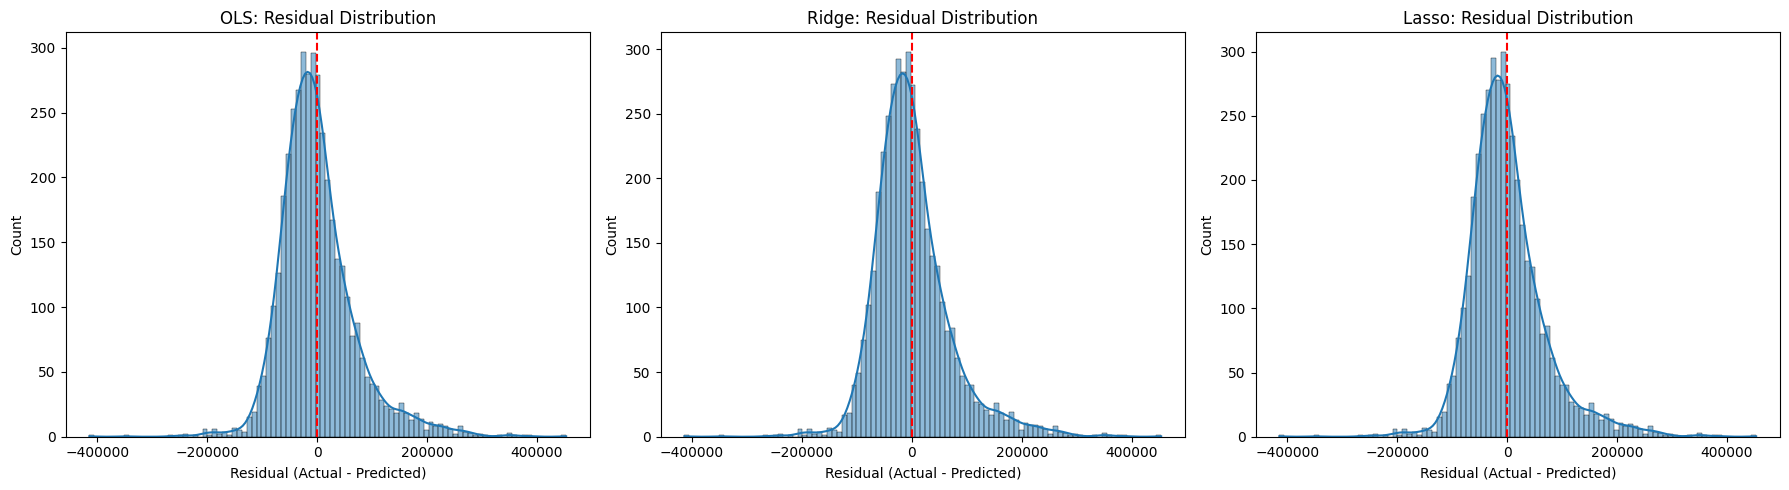

In [10]:
# Step 9: Residual distribution plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    sns.histplot(residuals, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [11]:
# Step 10: Check multicollinearity using VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use the scaled numerical training features
X_vif = pd.DataFrame(
    X_train_processed[:, :len(numeric_cols)],
    columns=numeric_cols
)

vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results.round(3))

,Feature,VIF
0,longitude,9.041
1,latitude,9.357
2,housing_median_age,1.259
3,total_rooms,18.701
4,total_bedrooms,49.750
5,population,6.816
6,households,45.996
7,median_income,2.127
8,rooms_per_household,1.775
9,bedrooms_per_room,2.775


# Task 2: Real Estate Housing Price Prediction

## 1. Objective
The objective of this project is to predict median house values using regression models and compare their performance.

## 2. Dataset
The project uses the California Housing dataset stored in housing.csv. The target variable is median_house_value.

## 3. Data Preprocessing
- Inspected the dataset and identified missing values.
- Imputed missing numerical values using the median.
- Imputed missing categorical values using the most frequent category.
- Created interaction features for rooms, bedrooms, population, and households.
- Encoded categorical variables using one-hot encoding.
- Standardized numerical features.
- Split the data into training and testing sets using an 80:20 ratio.

## 4. Models
- Ordinary Least Squares (OLS) Regression
- Ridge Regression
- Lasso Regression

Ridge and Lasso regularization strengths were selected using cross-validation.

## 5. Evaluation Metrics
The models were evaluated using:
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R-squared (R²)

The results table and actual-versus-predicted plots are included in this notebook.

## 6. Residual and Multicollinearity Analysis
Residual distributions were plotted to examine prediction errors. Variance Inflation Factor (VIF) was calculated to investigate multicollinearity among numerical features.

## 7. Conclusion
The three regression models were compared using the same test set. The final model assessment is based on the observed RMSE, MAE, R², and residual patterns.